# Redes Neuronales 2026 — Trabajo Práctico 1
## Simulación numérica del modelo de neuronas de Izhikevich

Notebook con el código completo del TP, según la **consigna actualizada (28/9/2026)** y con la estructura de la guía 6:

1. **Ejercicio 1.** Librerías e integradores (Euler, RK4 e `integrador_ode`).
2. **Ejercicio 2 (primera parte).** Modelo de Izhikevich en la notación del artículo ($a, b, c, d$): caso base (ítems 1 y 2) y los ocho paneles de la figura 2 con los protocolos de la consigna (ítem 3).
3. **Análisis extra** para la discusión: plano de fase, curva f–I, resonancia en RZ y error numérico (paso $h$ y tratamiento del reseteo).
4. **Ejercicio 3 (segunda parte, opcional).** Red de 1000 neuronas: traducción literal del Matlab (figura 3), comparación con y sin autoconexiones y los dos extras opcionales (Euler–Maruyama y $z(v)$).

Referencia: E. M. Izhikevich, *Simple model of spiking neurons*, IEEE Trans. Neural Netw. 14(6), 1569–1572 (2003).

## Ejercicio 1) Librerías e integradores

In [1]:
# 1.1)
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
# 1.2) Integradores de la guía 6
def euler(f, x, t, h, p):
    return x + h*f(x, t, p)

def rk4(f, x, t, h, p):
    k1 = f(x, t, p)
    k2 = f(x + 0.5*h*k1, t + 0.5*h, p)
    k3 = f(x + 0.5*h*k2, t + 0.5*h, p)
    k4 = f(x + h*k3, t + h, p)
    return x + h*(k1 + 2.0*k2 + 2.0*k3 + k4)/6.0

def integrador_ode(m, f, xa, a, b, k, p, c=lambda x, t, p: x):
    """Integra dx/dt = f(x,t,p) en [a,b] con k pasos del método m.
    c(x,t,p) es la 'función condicionante' que se aplica después de cada paso:
    acá la usamos para implementar el reseteo (el 'truquito' del disparo)."""
    assert k > 0
    n = len(xa)
    h = (b - a)/k
    w = np.zeros((n, k+1))
    t = np.zeros(k+1)
    w[:, 0] = xa
    t[0] = a
    for j in range(k):
        t[j+1] = t[j] + h
        w[:, j+1] = m(f, w[:, j], t[j], h, p)
        w[:, j+1] = c(w[:, j+1], t[j+1], p)
    return t, w

## Ejercicio 2) Modelo de Izhikevich (notación del artículo)

$$\dot v = 0.04\,v^2 + 5v + 140 - u + I(t), \qquad \dot u = a\,(b\,v - u)$$

con el reseteo: si $v \ge 30$ mV entonces $v \leftarrow c$ y $u \leftarrow u + d$.

* $v$: potencial de membrana [mV]; $u$: variable de recuperación (efecto neto de corrientes iónicas lentas, realimentación negativa sobre $v$); $I$: corriente inyectada o entrada sináptica efectiva.
* $a$: escala temporal de $u$; $b$: sensibilidad de $u$ a las variaciones subumbrales de $v$; $c$: valor de reseteo de $v$; $d$: incremento de $u$ en cada spike.
* **30 mV no es un umbral fisiológico**: es el valor que usa el algoritmo para registrar el pico del spike y aplicar el reseteo. La iniciación del spike depende del estado $(v, u)$.

El vector de parámetros es `p = (a, b, c, d, I, v_pico)`, donde `I` es **una función de t**.

In [3]:
V_PICO = 30.0   # valor que usa el algoritmo para registrar el pico y resetear (NO es un umbral fisiológico)

def izhikevich(x, t, p):
    a, b, c, d, I, vp = p
    v, u = x
    return np.array([0.04*v**2 + 5.0*v + 140.0 - u + I(t),
                     a*(b*v - u)])

def reseteo(x, t, p):
    a, b, c, d, I, vp = p
    if x[0] >= vp:                       # spike registrado
        return np.array([c, x[1] + d])   # v <- c, u <- u + d
    return x

def parametros(a=0.02, b=0.2, c=-65.0, d=2.0, I=None, v_pico=V_PICO):
    return (a, b, c, d, I, v_pico)

In [4]:
def reposo(b, I=0.0):
    """Punto fijo estable (raíz menor) de 0.04 v^2 + (5-b) v + 140 + I = 0, u* = b v*."""
    disc = (5.0 - b)**2 - 4*0.04*(140.0 + I)
    if disc < 0:
        return None
    return (-(5.0 - b) - np.sqrt(disc))/(2*0.04)

def tiempos_disparo(t, w, c=None):
    """Índices j en que se aplicó el reseteo (v salta hacia abajo hasta c)."""
    return np.flatnonzero(np.diff(w[0]) < -15) + 1

def con_picos(t, w, vp=V_PICO):
    """Para graficar: inserta un punto (t_s, 30 mV) antes de cada reseteo, como
    hace Izhikevich ('all spikes were equalized at +30 mV')."""
    j = tiempos_disparo(t, w)
    tt = np.insert(t, j, t[j])
    vv = np.insert(w[0], j, vp)
    return tt, vv

def simular(p, v0, T=200.0, h=0.1, metodo=rk4):
    """RK4 (o Euler) + reseteo después de cada paso, con u(0) = b v(0)."""
    b = p[1]
    k = int(round(T/h))
    return integrador_ode(metodo, izhikevich, np.array([v0, b*v0]), 0.0, T, k, p, reseteo)

### 2.1) Caso base: RK4 en $t\in[0,100]$ ms, $h=0.1$ ms

$a=0.02$, $b=0.2$, $c=-65$ mV, $d=2$; $I(t)=0$ si $t<10$ ms y $10$ si $t\ge 10$ ms; $v(0)=-70$ mV, $u(0)=b\,v(0)=-14$.
Después de cada paso de RK4 se verifica si $v\ge 30$ mV; si es así se registra el spike y se aplica inmediatamente el reseteo (función condicionante `reseteo`).

In [5]:
def escalon(t0, I0, Iantes=0.0):
    return lambda t: Iantes if t < t0 else I0

I_base = escalon(10, 10.0)
p = parametros(a=0.02, b=0.2, c=-65, d=2, I=I_base)
t, w = simular(p, v0=-70.0, T=100.0, h=0.1)
ts = t[tiempos_disparo(t, w)]
print('u(0) =', w[1, 0])
print('tiempos de disparo [ms]:', ts.round(1))
print('intervalos entre spikes [ms]:', np.diff(ts).round(1))

u(0) = -14.0
tiempos de disparo [ms]: [13.5 17.1 21.9 29.5 44.7 63.7 82.6]
intervalos entre spikes [ms]: [ 3.6  4.8  7.6 15.2 19.  18.9]


### 2.2) Gráfico de v(t), u(t) e I(t), con el inicio del estímulo y los tiempos de disparo

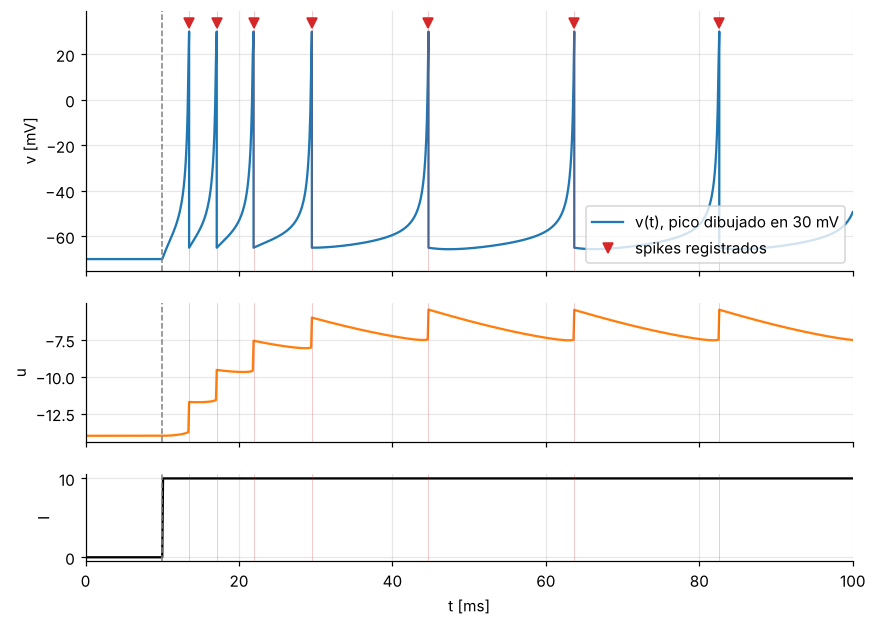

In [6]:
tt, vv = con_picos(t, w)
fig, ax = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.6, 1]})
ax[0].plot(tt, vv, label='v(t), pico dibujado en 30 mV')
ax[0].plot(ts, np.full(ts.size, 34), 'v', color='tab:red', label='spikes registrados')
ax[0].set_ylabel('v [mV]'); ax[0].legend(loc='lower right')
ax[1].plot(t, w[1], color='tab:orange'); ax[1].set_ylabel('u')
ax[2].plot(t, [I_base(x) for x in t], color='k'); ax[2].set_ylabel('I'); ax[2].set_xlabel('t [ms]')
for a in ax:
    a.axvline(10, color='gray', ls='--', lw=1)            # inicio del estímulo
    for x in ts: a.axvline(x, color='tab:red', lw=0.4, alpha=0.4)
ax[0].set_xlim(0, 100)
plt.show()

### 2.3) Los ocho paneles de la figura 2 del artículo

| Caso | a | b | c | d | I | v(0) |
|---|---|---|---|---|---|---|
| RS | 0.02 | 0.20 | −65 | 8 | I₁ | −65 |
| IB | 0.02 | 0.20 | −55 | 4 | I₁ | −65 |
| CH | 0.02 | 0.20 | −50 | 2 | I₁ | −65 |
| FS | 0.10 | 0.20 | −65 | 2 | I₁ | −65 |
| TC1 | 0.02 | 0.25 | −65 | 0.05 | I₂ | −63 |
| TC2 | 0.02 | 0.25 | −65 | 0.05 | I₃ | −65 |
| RZ | 0.10 | 0.26 | −65 | 2 | I₄ | −62.5 |
| LTS | 0.02 | 0.25 | −65 | 2 | I₁ | −65 |

Siempre $u(0)=b\,v(0)$ y $h=0.1$ ms. Corrientes de la consigna:
* $I_1$: 0 si $t<20$, 10 si $t\ge 20$ ms.
* $I_2$ (TC1, disparo tónico desde el reposo): 0 si $t<20$, 1 si $t\ge20$ ms.
* $I_3$ (TC2, rebound burst): $-25$ en $20\le t<80$ ms, 0 fuera.
* $I_4$ (RZ): 0 si $t<40$; 0.2 en $[40,180)$; 2.2 en $[180,181)$; 0.2 desde 181 ms.

Duración: 200 ms (300 ms para RZ, para ver el disparo repetitivo después del pulso).

In [7]:
def pulso(t0, t1, I0, Ifuera=0.0):
    return lambda t: I0 if t0 <= t < t1 else Ifuera

I1 = escalon(20, 10.0)                  # RS, IB, CH, FS, LTS
I2 = escalon(20, 1.0)                   # TC1 (disparo tónico desde el reposo)
I3 = pulso(20, 80, -25.0)               # TC2 (hiperpolarización y rebound burst)
def I4(t):                              # RZ (corriente chica + pulso breve)
    if t < 40:   return 0.0
    if t < 180:  return 0.2
    if t < 181:  return 2.2
    return 0.2

#           a     b     c     d     I    v(0)
CASOS = {
    'RS':  (0.02, 0.20, -65, 8.00, I1, -65.0),
    'IB':  (0.02, 0.20, -55, 4.00, I1, -65.0),
    'CH':  (0.02, 0.20, -50, 2.00, I1, -65.0),
    'FS':  (0.10, 0.20, -65, 2.00, I1, -65.0),
    'TC1': (0.02, 0.25, -65, 0.05, I2, -63.0),
    'TC2': (0.02, 0.25, -65, 0.05, I3, -65.0),
    'RZ':  (0.10, 0.26, -65, 2.00, I4, -62.5),
    'LTS': (0.02, 0.25, -65, 2.00, I1, -65.0),
}
# duración de cada simulación (la consigna permite ajustarla para que se vea la dinámica)
DURACION = {'RS': 200, 'IB': 200, 'CH': 200, 'FS': 200, 'LTS': 200,
            'TC1': 200, 'TC2': 200, 'RZ': 300}

NOMBRES = {'RS': 'regular spiking (RS)', 'IB': 'intrinsically bursting (IB)',
           'CH': 'chattering (CH)', 'FS': 'fast spiking (FS)',
           'TC1': 'thalamo-cortical (TC1), disparo tónico', 'TC2': 'thalamo-cortical (TC2), rebound burst',
           'RZ': 'resonator (RZ)', 'LTS': 'low-threshold spiking (LTS)'}

def p_caso(nombre):
    a, b, c, d, I, v0 = CASOS[nombre]
    return parametros(a=a, b=b, c=c, d=d, I=I)

def simular_caso(nombre, h=0.1, metodo=rk4, v0=None, T=None):
    v0 = CASOS[nombre][5] if v0 is None else v0
    return simular(p_caso(nombre), v0, T=T or DURACION[nombre], h=h, metodo=metodo)

RS   v(0)= -65.0  spikes=  5  primeros t: [ 23.8  45.   89.9 134.8 179.7]
IB   v(0)= -65.0  spikes=  8  primeros t: [ 23.8  26.1  30.   69.2 100.5 131.9]
CH   v(0)= -65.0  spikes= 17  primeros t: [23.8 25.2 26.7 28.4 30.3 32.6]
FS   v(0)= -65.0  spikes= 25  primeros t: [23.6 27.7 33.4 40.4 47.8 55.3]
TC1  v(0)= -63.0  spikes=  4  primeros t: [ 33.3  57.5 102.7 152.9]
TC2  v(0)= -65.0  spikes=  5  primeros t: [ 87.2  92.7  99.3 108.  123.2]


RZ   v(0)= -62.5  spikes=  3  primeros t: [193.9 236.2 278.5]
LTS  v(0)= -65.0  spikes= 17  primeros t: [22.4 25.3 28.8 33.3 39.7 49.8]


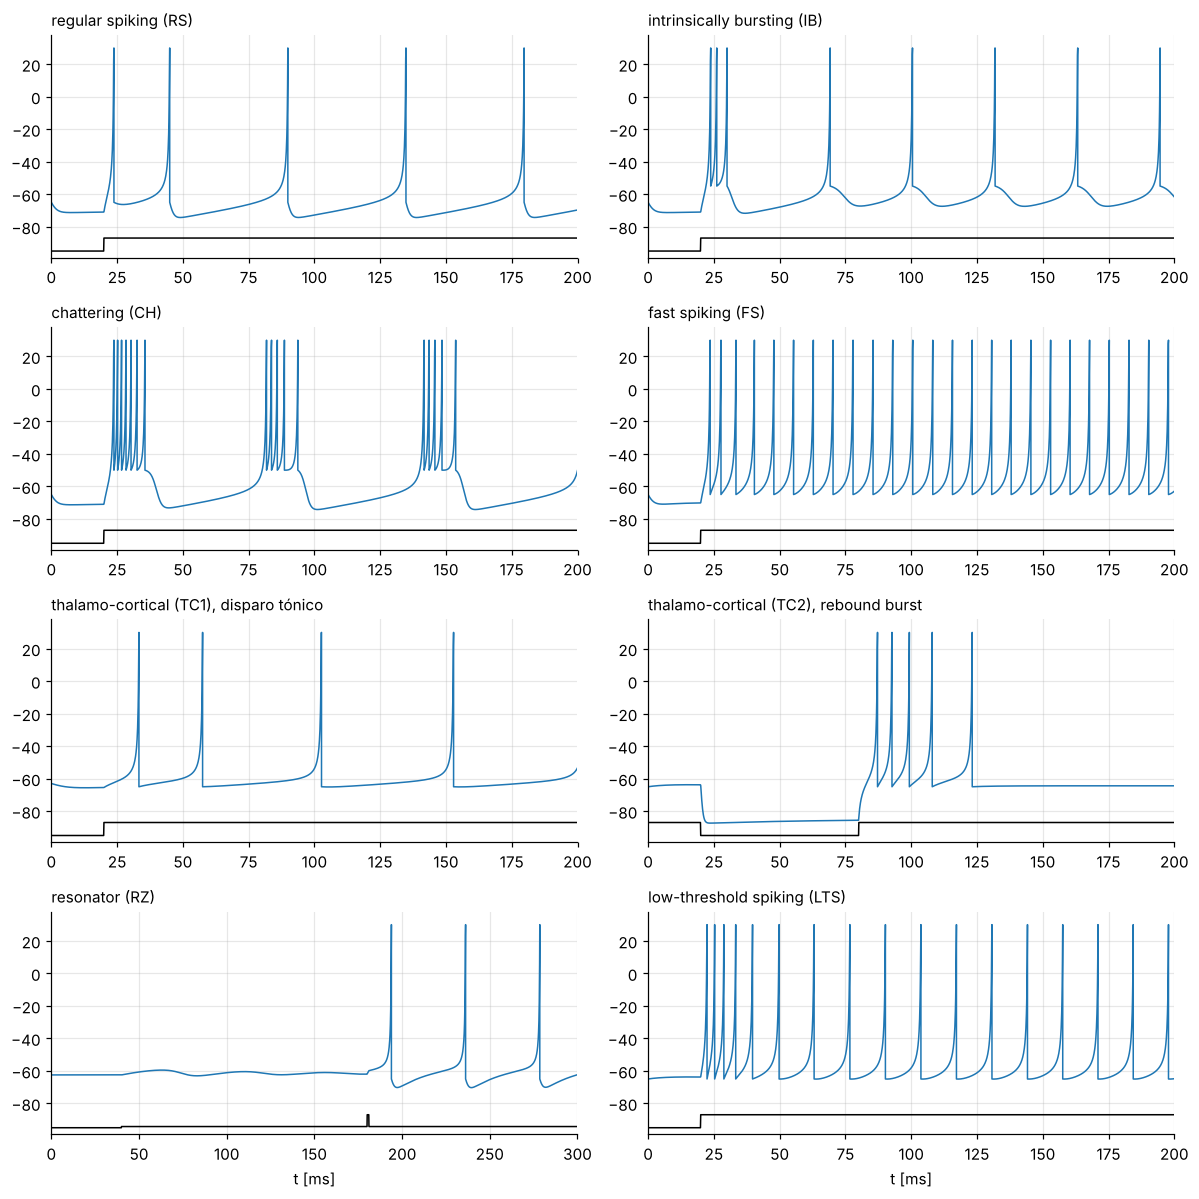

In [8]:
fig, axs = plt.subplots(4, 2, figsize=(11, 11))
for ax, nombre in zip(axs.flatten(), CASOS):
    t, w = simular_caso(nombre)
    tt, vv = con_picos(t, w)
    Iv = np.array([CASOS[nombre][4](x) for x in t])
    ax.plot(tt, vv, lw=1)
    ax.plot(t, -95 + 8*(Iv - Iv.min())/max(np.ptp(Iv), 1e-9), color='k', lw=1)   # corriente, escalada
    ax.set_title(NOMBRES[nombre], loc='left', fontsize=10); ax.set_ylim(-99, 38); ax.set_xlim(0, t[-1])
    print(f'{nombre:4s} v(0)={CASOS[nombre][5]:6.1f}  spikes={len(tiempos_disparo(t, w)):3d}  primeros t:', t[tiempos_disparo(t, w)][:6].round(1))
for a in axs[-1]: a.set_xlabel('t [ms]')
fig.tight_layout(); plt.show()

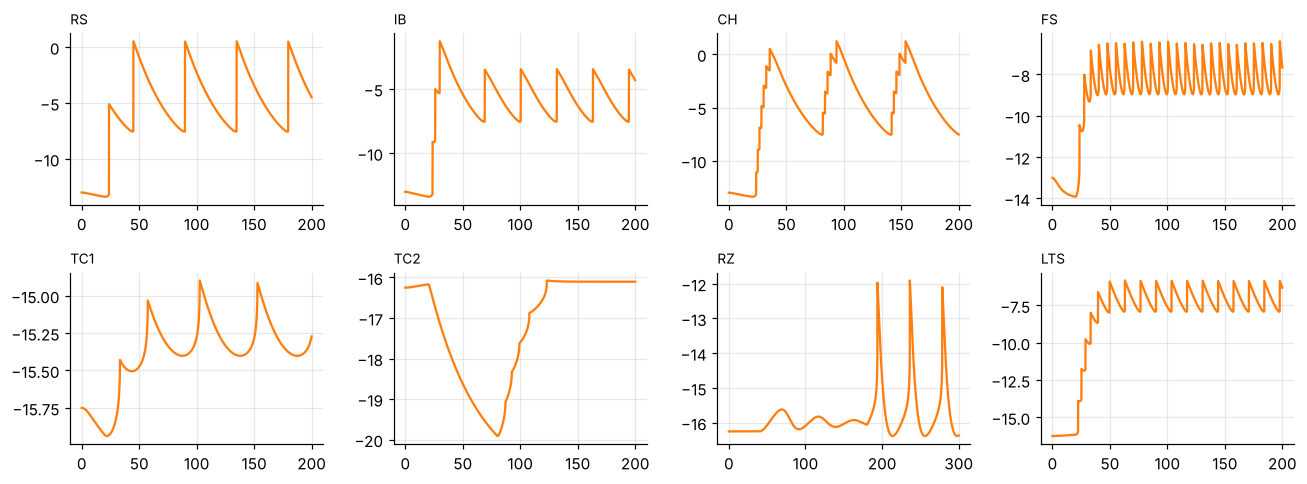

In [9]:
# Variable de recuperación u(t) en los ocho casos
fig, axs = plt.subplots(2, 4, figsize=(12, 4.5))
for ax, nombre in zip(axs.flatten(), CASOS):
    t, w = simular_caso(nombre)
    ax.plot(t, w[1], color='tab:orange'); ax.set_title(nombre, loc='left', fontsize=9)
fig.tight_layout(); plt.show()

**Qué distingue a cada tipo** (para comparar con la figura 2 del artículo):
RS dispara con adaptación (intervalos que se alargan, $d=8$ grande); IB hace un burst inicial y luego spikes aislados ($c=-55$ alto); CH repite bursts de alta frecuencia ($c=-50$ aún más alto, $d=2$); FS dispara rápido y casi sin adaptación ($a=0.1$: $u$ se recupera rápido); LTS dispara rápido con adaptación ($b=0.25$: umbral bajo); TC1 dispara tónicamente con una corriente chica; TC2 hace un rebound burst al terminar la hiperpolarización ($b=0.25$: durante el pulso negativo $u$ baja y al soltarlo $v$ se dispara); RZ muestra oscilaciones subumbrales amortiguadas y un pulso breve en el instante adecuado lo pasa al disparo repetitivo (resonancia, $b=0.26$).

## Análisis extra (para la discusión)

### 1) Bifurcaciones del reposo
Puntos fijos: $u^*=b\,v^*$ y $0.04\,v^{*2} + (5-b)v^* + 140 + I = 0$.
Silla-nodo en $I_{SN}=(5-b)^2/0.16-140$; Hopf cuando $\mathrm{tr}\,J = 0.08\,v^*+5-a=0$ con $\det J>0$ (ocurre antes si $b>a$).

In [10]:
def bifurcaciones(a, b):
    I_sn = (5 - b)**2/(4*0.04) - 140
    vH = (a - 5)/(2*0.04)
    I_h = -(0.04*vH**2 + (5 - b)*vH + 140)
    det_ok = a*(b - (0.08*vH + 5)) > 0
    return I_sn, (I_h if (det_ok and b > a) else None)

for nombre in ['RS', 'FS', 'LTS', 'RZ']:
    a, b = CASOS[nombre][:2]
    I_sn, I_h = bifurcaciones(a, b)
    print(f'{nombre}: v* = {reposo(b):6.2f} mV   I_SN = {I_sn:6.3f}   I_Hopf = {I_h if I_h is None else round(I_h, 3)}')

RS: v* = -70.00 mV   I_SN =  4.000   I_Hopf = 3.797
FS: v* = -70.00 mV   I_SN =  4.000   I_Hopf = 3.938
LTS: v* = -64.41 mV   I_SN =  1.016   I_Hopf = 0.685
RZ: v* = -62.50 mV   I_SN =  0.423   I_Hopf = 0.262


### 2) Plano de fase (RS y CH) con nulclinas

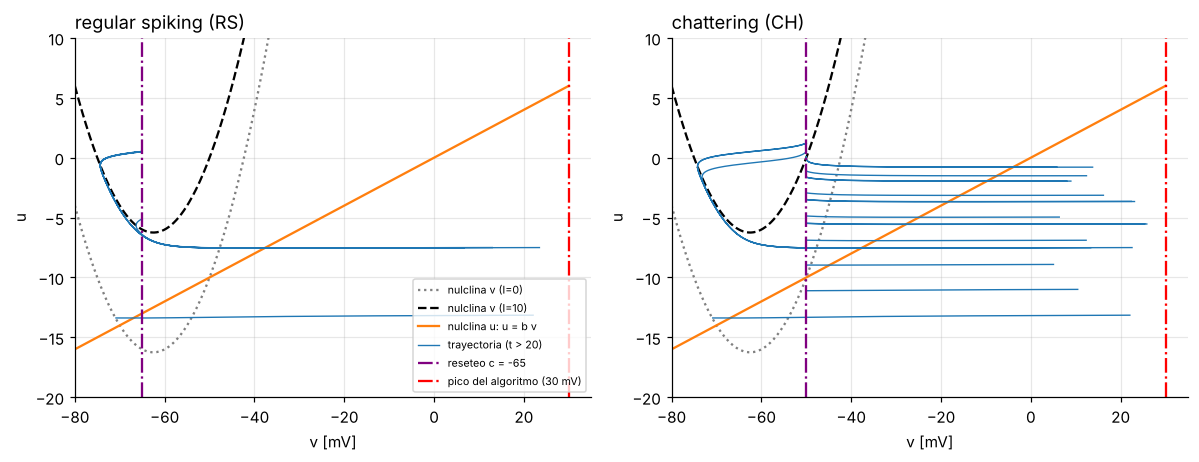

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, nombre in zip(axs, ['RS', 'CH']):
    a, b, c, d, _, _ = CASOS[nombre]
    t, w = simular_caso(nombre)
    V = np.linspace(-80, 30, 400)
    ax.plot(V, 0.04*V**2 + 5*V + 140, ':', color='gray', label='nulclina v (I=0)')
    ax.plot(V, 0.04*V**2 + 5*V + 140 + 10, '--', color='k', label='nulclina v (I=10)')
    ax.plot(V, b*V, color='tab:orange', label='nulclina u: u = b v')
    jr = tiempos_disparo(t, w)
    vv_ = np.insert(w[0], jr, np.nan); uu_ = np.insert(w[1], jr, np.nan); tq = np.insert(t, jr, t[jr])
    ax.plot(vv_[tq >= 20], uu_[tq >= 20], lw=0.9, label='trayectoria (t > 20)')
    ax.axvline(c, color='purple', ls='-.', label=f'reseteo c = {c}'); ax.axvline(30, color='red', ls='-.', label='pico del algoritmo (30 mV)')
    ax.set_xlim(-80, 35); ax.set_ylim(-20, 10); ax.set_xlabel('v [mV]'); ax.set_ylabel('u'); ax.set_title(NOMBRES[nombre], loc='left')
axs[0].legend(fontsize=7); fig.tight_layout(); plt.show()

### 3) Curva f–I (frecuencia estacionaria vs corriente constante)

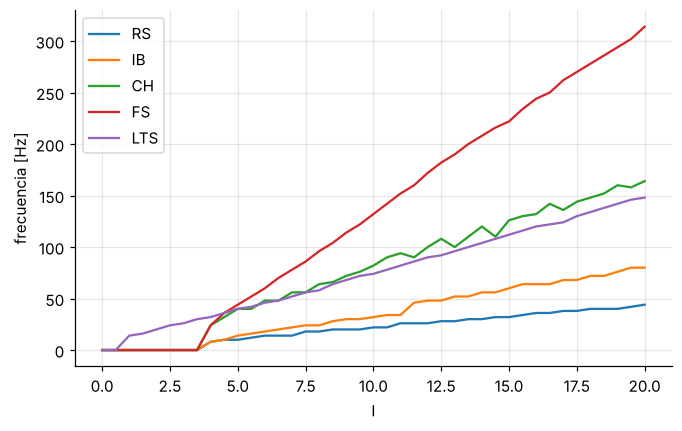

In [12]:
Is = np.linspace(0, 20, 41)
plt.figure(figsize=(7, 4.2))
for nombre in ['RS', 'IB', 'CH', 'FS', 'LTS']:
    a, b, c, d = CASOS[nombre][:4]
    fr = []
    for I0 in Is:
        t, w = simular(parametros(a, b, c, d, I=lambda t, I0=I0: I0), reposo(b), T=1000)
        ts = t[tiempos_disparo(t, w)]; fr.append(1000*np.sum(ts > 500)/500)
    plt.plot(Is, fr, label=nombre)
plt.xlabel('I'); plt.ylabel('frecuencia [Hz]'); plt.legend(); plt.show()

### 4) Resonancia en RZ: el pulso dispara o no según la fase de la oscilación subumbral
Con $I=0.2$ el reposo de RZ es un foco estable: $v$ oscila amortiguadamente. Barremos el instante $t_p$ del pulso de 1 ms y amplitud 2.2.

el pulso NO dispara para t_p en: [ 73.  74.  75.  76.  77.  78.  79.  80.  81.  82.  83.  84.  85. 123.
 124. 125. 126. 127. 128. 129. 130.]


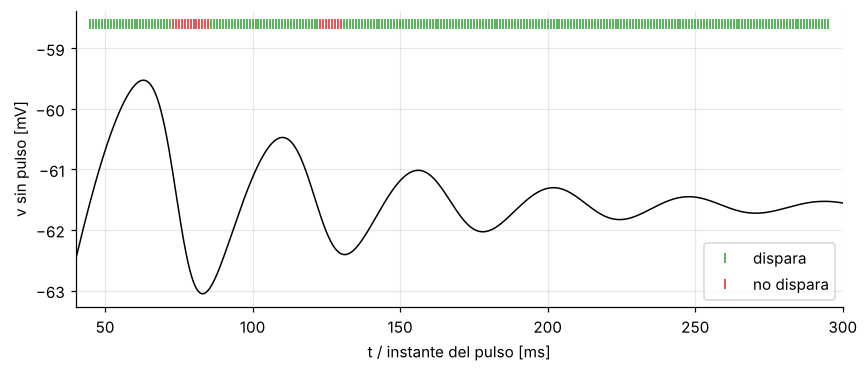

In [13]:
a, b, c, d, _, v0 = CASOS['RZ']
I_sin = lambda t: 0.0 if t < 40 else 0.2
t0, w0 = simular(parametros(a, b, c, d, I_sin), v0, T=300)
tps = np.arange(45, 296, 1.0); exito = []
for tp in tps:
    I = lambda t, tp=tp: 0.0 if t < 40 else (2.2 if tp <= t < tp + 1 else 0.2)
    t, w = simular(parametros(a, b, c, d, I), v0, T=tp + 50)
    exito.append(len(tiempos_disparo(t, w)) > 0)
exito = np.array(exito)
print('el pulso NO dispara para t_p en:', tps[~exito])
plt.figure(figsize=(9, 3.5))
plt.plot(t0, w0[0], 'k', lw=1)
plt.plot(tps[exito], np.full(exito.sum(), -58.6), '|', color='tab:green', label='dispara')
plt.plot(tps[~exito], np.full((~exito).sum(), -58.6), '|', color='tab:red', label='no dispara')
plt.xlim(40, 300); plt.xlabel('t / instante del pulso [ms]'); plt.ylabel('v sin pulso [mV]'); plt.legend(); plt.show()

### 5) Error numérico: paso $h$ y tratamiento del reseteo
Referencia: `scipy.integrate.solve_ivp` (DOP853, tolerancias $10^{-11}$) con detección exacta del evento $v=30$.
Se compara Euler, RK4 con reseteo al final del paso (lo que pide la consigna) y RK4 localizando el cruce dentro del paso.

In [14]:
def integrador_eventos(f, xa, a, b, k, p):
    """RK4 + localización del cruce v = 30 por interpolación lineal dentro del paso.
    Devuelve la trayectoria en la grilla y los tiempos de disparo 'exactos'."""
    c, d, vp = p[2], p[3], p[5]
    h = (b - a)/k
    t = a + h*np.arange(k+1)
    w = np.zeros((len(xa), k+1)); w[:, 0] = xa
    spikes = []
    for j in range(k):
        x = w[:, j]
        y = rk4(f, x, t[j], h, p)
        if y[0] >= vp:
            th = (vp - x[0])/(y[0] - x[0])           # fracción del paso donde cruza
            xs = rk4(f, x, t[j], th*h, p)             # avanzo hasta el cruce
            ts = t[j] + th*h
            spikes.append(ts)
            xs = np.array([c, xs[1] + d])             # reseteo en el instante del cruce
            y = rk4(f, xs, ts, (1 - th)*h, p)         # completo el paso
        w[:, j+1] = y
    return t, w, np.array(spikes)

referencia: [ 23.741  44.696  89.552 134.365 179.177]


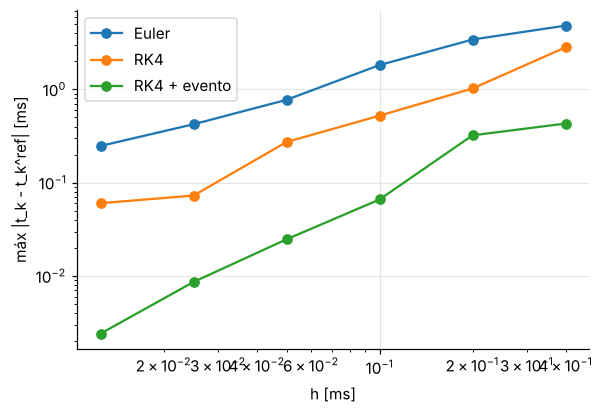

In [15]:
from scipy.integrate import solve_ivp

def spikes_referencia(p, v0, T=200.0, cortes=(20.0,)):
    a, b, c, d, I, vp = p
    x = np.array([v0, b*v0]); t0 = 0.0; out = []
    ev = lambda t, x: x[0] - vp; ev.terminal = True; ev.direction = 1
    while t0 < T:
        tf = min([s for s in cortes if s > t0] + [T])
        s = solve_ivp(lambda t, x: izhikevich(x, t, p), (t0, tf), x, events=ev,
                      rtol=1e-11, atol=1e-11, method='DOP853', max_step=0.05)
        if s.status == 1:
            t0 = s.t_events[0][0]; out.append(t0); xs = s.y_events[0][0]; x = np.array([c, xs[1] + d])
        else:
            x = s.y[:, -1]; t0 = tf
    return np.array(out)

p = p_caso('RS'); v0 = CASOS['RS'][5]
tref = spikes_referencia(p, v0)
print('referencia:', tref.round(3))
hs = [0.4, 0.2, 0.1, 0.05, 0.025, 0.0125]
err = {'Euler': [], 'RK4': [], 'RK4 + evento': []}
for h in hs:
    for nm, m in [('Euler', euler), ('RK4', rk4)]:
        t, w = simular(p, v0, T=200, h=h, metodo=m); ts = t[tiempos_disparo(t, w)]
        err[nm].append(np.max(np.abs(ts - tref)) if len(ts) == len(tref) else np.nan)
    t, w, ts = integrador_eventos(izhikevich, np.array([v0, p[1]*v0]), 0, 200, int(round(200/h)), p)
    err['RK4 + evento'].append(np.max(np.abs(ts - tref)) if len(ts) == len(tref) else np.nan)
plt.figure(figsize=(6, 4))
for k, v in err.items(): plt.loglog(hs, v, 'o-', label=k)
plt.xlabel('h [ms]'); plt.ylabel('máx |t_k - t_k^ref| [ms]'); plt.legend(); plt.show()

**Lectura:** RK4 es de orden 4 entre spikes, pero si el reseteo se aplica recién al final del paso, el tiempo de disparo queda redondeado a la grilla y el error es $O(h)$. Localizando el cruce dentro del paso se recupera un orden mayor. Por eso importan tanto el paso $h$ como el tratamiento de la condición de reseteo.

## Ejercicio 3) Red de 1000 neuronas de Izhikevich (segunda parte, opcional)

$N_e=800$ excitatorias, $N_i=200$ inhibitorias, $r_i\sim U(0,1)$:
* excitatorias: $a=0.02$, $b=0.2$, $c=-65+15r_i^2$, $d=8-6r_i^2$ (de RS a CH);
* inhibitorias: $a=0.02+0.08r_i$, $b=0.25-0.05r_i$, $c=-65$, $d=2$ (de LTS a FS);
* $S=[\,0.5\,R_E \mid -R_I\,]$, con $s_{ij}$ el peso de la presináptica $j$ a la postsináptica $i$.

En cada paso de 1 ms: ruido talámico $I^{ext}_i = 5\xi_i$ (exc.) o $2\xi_i$ (inh.), entrada sináptica **por pulsos** $I^{syn}_i=\sum_{j\in F} s_{ij}$ (F = neuronas que dispararon), dos medios pasos de Euler de 0.5 ms para $v$ y uno de 1 ms para $u$.

### 3.1) Traducción literal del código Matlab del artículo

In [16]:
SEMILLA = 2026          # semilla reportada en el informe

def parametros_red(Ne=800, Ni=200, seed=SEMILLA, autoconexiones=True):
    """Mismo orden de sorteos que el Matlab: re, ri, después S.
    Con la misma semilla, las variantes con y sin diagonal comparten r_i, S y ruido."""
    rng = np.random.default_rng(seed)
    re, ri = rng.random(Ne), rng.random(Ni)
    a = np.r_[0.02*np.ones(Ne), 0.02 + 0.08*ri]
    b = np.r_[0.2*np.ones(Ne),  0.25 - 0.05*ri]
    c = np.r_[-65 + 15*re**2,   -65*np.ones(Ni)]       # -65 + 15 r^2 (paper)
    d = np.r_[8 - 6*re**2,       2*np.ones(Ni)]
    N = Ne + Ni
    S = np.hstack([0.5*rng.random((N, Ne)), -rng.random((N, Ni))])   # s_ij: de j (pre) a i (post)
    if not autoconexiones:
        np.fill_diagonal(S, 0.0)
    return dict(Ne=Ne, Ni=Ni, N=N, a=a, b=b, c=c, d=d, S=S, rng=rng)

def ruido_talamico(p):
    """I_ext: 5 xi para excitatorias, 2 xi para inhibitorias, xi ~ N(0,1), renovado cada 1 ms."""
    return np.r_[5*p['rng'].standard_normal(p['Ne']), 2*p['rng'].standard_normal(p['Ni'])]

def red_literal(p, T=1000):
    """Un paso = 1 ms. Detección (v >= 30) y reseteo al principio del paso,
    entrada sináptica por pulsos I_syn = sum_{j en F} s_ij, y dos medios pasos de Euler para v."""
    v = -65.0*np.ones(p['N']); u = p['b']*v
    firings = []
    for t in range(T):
        I = ruido_talamico(p)
        fired = np.flatnonzero(v >= 30)
        firings += [(t, i) for i in fired]
        v[fired] = p['c'][fired]
        u[fired] += p['d'][fired]
        I += p['S'][:, fired].sum(axis=1)                    # acoplamiento por eventos de spike
        v += 0.5*(0.04*v**2 + 5*v + 140 - u + I)             # "for numerical stability"
        v += 0.5*(0.04*v**2 + 5*v + 140 - u + I)
        u += p['a']*(p['b']*v - u)
    return np.array(firings, dtype=float).reshape(-1, 2)

def metricas(firings, T, N=1000, Ne=800, desde=0.0):
    """Total de spikes y tasas medias (Hz por neurona) en [desde, T)."""
    m = firings[:, 0] >= desde
    t, i = firings[m, 0], firings[m, 1]
    dur = (T - desde)*1e-3
    return dict(spikes=int(t.size), tasa_Hz=float(t.size/(N*dur)),
                tasa_exc_Hz=float((i < Ne).sum()/(Ne*dur)), tasa_inh_Hz=float((i >= Ne).sum()/((N-Ne)*dur)))

def actividad_poblacional(firings, T, N=1000, bin_ms=1.0):
    bins = np.arange(0, T + bin_ms, bin_ms)
    cuentas, _ = np.histogram(firings[:, 0], bins)
    return bins[:-1], cuentas/(N*bin_ms*1e-3)               # Hz por neurona

def espectro(firings, T, N=1000, descartar=100.0):
    from scipy.signal import welch
    tb, tasa = actividad_poblacional(firings, T, N)
    x = tasa[tb >= descartar]
    f, P = welch(x - x.mean(), fs=1000, nperseg=min(512, x.size))
    return f, P

### 3.2) Raster tipo figura 3 (1000 ms, semilla 2026)

literal: {'spikes': 7765, 'tasa_Hz': 7.765, 'tasa_exc_Hz': 7.815, 'tasa_inh_Hz': 7.565} 
  sin el transitorio inicial (t > 100 ms): {'spikes': 6784, 'tasa_Hz': 7.5377777777777775, 'tasa_exc_Hz': 7.615277777777778, 'tasa_inh_Hz': 7.227777777777778}


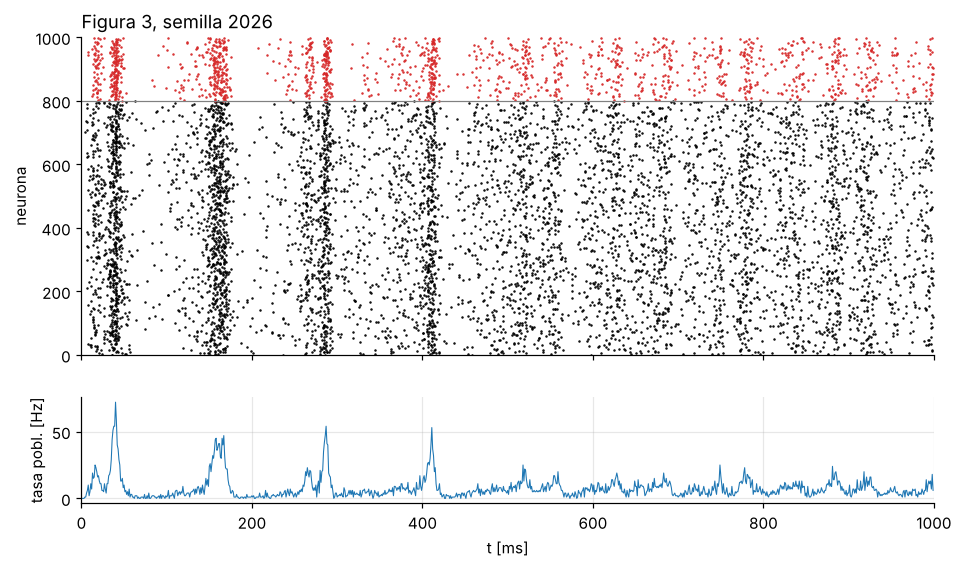

In [17]:
def raster(ax, f, ne=800, T=1000):
    e = f[:, 1] < ne
    ax.plot(f[e, 0], f[e, 1], '.', ms=1.2, color='k')
    ax.plot(f[~e, 0], f[~e, 1], '.', ms=1.2, color='tab:red')
    ax.axhline(ne, color='gray', lw=0.8); ax.set_ylim(0, 1000); ax.set_xlim(0, T); ax.grid(False); ax.set_ylabel('neurona')

T = 1000
f_lit = red_literal(parametros_red(seed=SEMILLA), T=T)
print('literal:', metricas(f_lit, T), '\n  sin el transitorio inicial (t > 100 ms):', metricas(f_lit, T, desde=100))
tb, tasa = actividad_poblacional(f_lit, T)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
raster(a1, f_lit); a1.set_title(f'Figura 3, semilla {SEMILLA}', loc='left')
a2.plot(tb, tasa, lw=0.7); a2.set_ylabel('tasa pobl. [Hz]'); a2.set_xlabel('t [ms]')
plt.show()

Se ve actividad asincrónica de fondo (spikes dispersos, ~7–8 Hz por neurona) interrumpida por episodios de sincronización: bandas verticales en las que gran parte de la población dispara junta, con un ritmo cercano a alfa (≈ 8–10 Hz en el espectro). El primer episodio (t ≈ 40 ms) es un transitorio: todas las neuronas arrancan en $v=-65$.

### 3.3) Con y sin autoconexiones (misma semilla)
La matriz densa del Matlab no anula la diagonal: hay $s_{ii}\neq 0$. Comparamos con $s_{ii}=0$; con la misma semilla las dos variantes comparten $r_i$, $S$ fuera de la diagonal y el ruido.

con diagonal: {'spikes': 7765, 'tasa_Hz': 7.765, 'tasa_exc_Hz': 7.815, 'tasa_inh_Hz': 7.565}
sin diagonal: {'spikes': 7561, 'tasa_Hz': 7.561, 'tasa_exc_Hz': 7.64375, 'tasa_inh_Hz': 7.23}


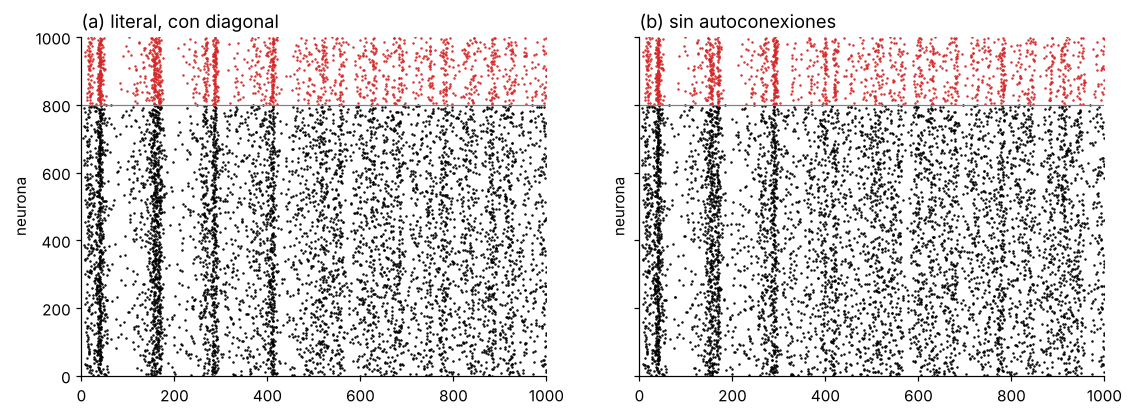

20 semillas: con 7.19±0.13 Hz, sin 7.17±0.13 Hz, diferencia 0.021±0.115 Hz


In [18]:
f_sin = red_literal(parametros_red(seed=SEMILLA, autoconexiones=False), T=T)
print('con diagonal:', metricas(f_lit, T)); print('sin diagonal:', metricas(f_sin, T))
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
raster(axs[0], f_lit); axs[0].set_title('(a) literal, con diagonal', loc='left')
raster(axs[1], f_sin); axs[1].set_title('(b) sin autoconexiones', loc='left')
plt.show()

comp = []
for s in range(1, 21):
    comp.append([metricas(red_literal(parametros_red(seed=s, autoconexiones=x), T=T), T, desde=100)['tasa_Hz'] for x in (True, False)])
comp = np.array(comp); dif = comp[:, 0] - comp[:, 1]
print(f'20 semillas: con {comp[:,0].mean():.2f}±{comp[:,0].std():.2f} Hz, sin {comp[:,1].mean():.2f}±{comp[:,1].std():.2f} Hz, diferencia {dif.mean():.3f}±{dif.std():.3f} Hz')

La diagonal aporta a cada neurona un único peso (≤ 0.5 mV si es excitatoria, ≥ −1 mV si es inhibitoria) frente a la suma de ~1000 entradas: quitarla cambia los spikes individuales (las trayectorias divergen por el caos de la red) pero no la estadística ni la dinámica cualitativa.

### 3.4) Extra opcional: Euler–Maruyama con ruido blanco continuo
Entre spikes, $dV_i = (0.04V_i^2+5V_i+140-U_i)\,dt + \sigma_i\,dW_i$, $dU_i=a_i(b_iV_i-U_i)\,dt$, con $\sigma_i = 5$ (exc.) o 2 (inh.), y los saltos sinápticos y el reseteo por separado. El incremento de Wiener en un paso $h$ tiene varianza $h$, por eso aparece $\sqrt h$. En el Matlab original **no** va $\sqrt h$: allí el ruido es una corriente que se sortea una vez por milisegundo (una secuencia discreta), no un proceso de Wiener.

In [19]:
def red_euler_maruyama(p, T=1000.0, h=0.1):
    """dV = (0.04V^2+5V+140-U) dt + sigma dW entre spikes; saltos sinápticos y reseteo por separado.
    El incremento de Wiener en un paso h tiene desvío sqrt(h): Y_{n+1} = Y_n + f h + sigma sqrt(h) xi."""
    sigma = np.r_[5*np.ones(p['Ne']), 2*np.ones(p['Ni'])]
    v = -65.0*np.ones(p['N']); u = p['b']*v
    k = int(round(T/h))
    firings = []
    for n in range(k):
        fired = np.flatnonzero(v >= 30)
        firings += [(n*h, i) for i in fired]
        v[fired] = p['c'][fired]
        u[fired] += p['d'][fired]
        v += p['S'][:, fired].sum(axis=1)                    # salto sináptico (misma amplitud que el original)
        fv = 0.04*v**2 + 5*v + 140 - u
        fu = p['a']*(p['b']*v - u)
        v = v + fv*h + sigma*np.sqrt(h)*p['rng'].standard_normal(p['N'])
        u = u + fu*h
    return np.array(firings, dtype=float).reshape(-1, 2)

### 3.5) Extra opcional: acoplamiento continuo con $z(v)=\frac{87+v}{450}-0.0193$
Propuesta explícita: se reemplaza el término por pulsos por la corriente continua $I^{syn}_i(t)=\sum_j s_{ij}\,z(v_j(t))$ (todo lo demás igual al Matlab). $z(v)$ no es un detector de spikes: vale ≈ 0.03 en el reposo, así que cada neurona recibe todo el tiempo una entrada de fondo. **Es un modelo distinto del de la figura 3**; se usa sólo como experimento comparativo.

In [20]:
def z(v):
    """z(v) = (87+v)/450 - 0.0193, con v recortado en 30 mV (v puede pasarse de 30 dentro del paso)."""
    return (87.0 + np.minimum(v, 30.0))/450.0 - 0.0193

def red_z(p, T=1000):
    """Igual que red_literal, pero la entrada sináptica es continua:
        I_syn,i(t) = sum_j s_ij z(v_j(t))      (en lugar de sum_{j en F} s_ij).
    Es un modelo distinto del de la figura 3: experimento comparativo, no reproducción."""
    v = -65.0*np.ones(p['N']); u = p['b']*v
    firings = []
    for t in range(T):
        I = ruido_talamico(p)
        I += p['S'] @ z(v)                                   # acoplamiento continuo (v antes del reseteo)
        fired = np.flatnonzero(v >= 30)
        firings += [(t, i) for i in fired]
        v[fired] = p['c'][fired]
        u[fired] += p['d'][fired]
        v += 0.5*(0.04*v**2 + 5*v + 140 - u + I)
        v += 0.5*(0.04*v**2 + 5*v + 140 - u + I)
        u += p['a']*(p['b']*v - u)
    return np.array(firings, dtype=float).reshape(-1, 2)

literal         {'spikes': 6784, 'tasa_Hz': 7.5377777777777775, 'tasa_exc_Hz': 7.615277777777778, 'tasa_inh_Hz': 7.227777777777778}
Euler-Maruyama  {'spikes': 7411, 'tasa_Hz': 8.234444444444444, 'tasa_exc_Hz': 8.126388888888888, 'tasa_inh_Hz': 8.666666666666666}
z(v)            {'spikes': 7506, 'tasa_Hz': 8.34, 'tasa_exc_Hz': 8.38888888888889, 'tasa_inh_Hz': 8.144444444444444}


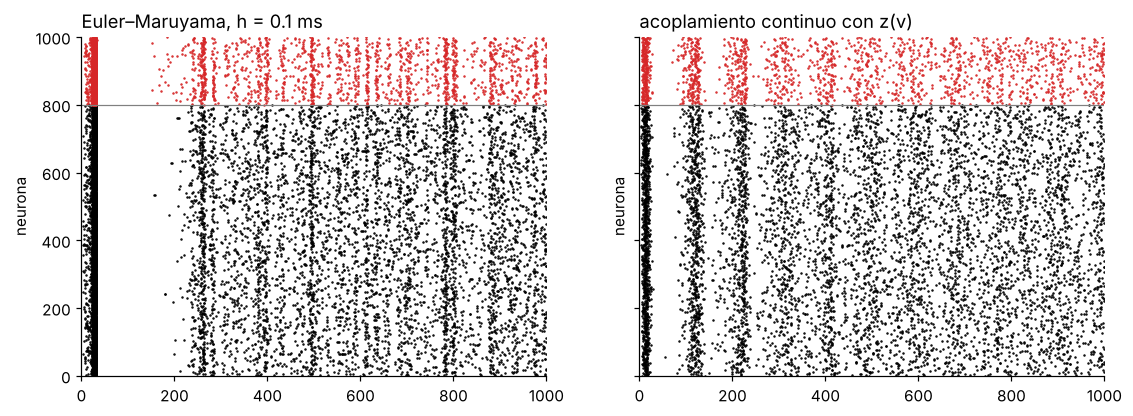

In [21]:
f_em = red_euler_maruyama(parametros_red(seed=SEMILLA), T=T, h=0.1)
f_z = red_z(parametros_red(seed=SEMILLA), T=T)
for nm, f in [('literal', f_lit), ('Euler-Maruyama', f_em), ('z(v)', f_z)]:
    print(f'{nm:15s}', metricas(f, T, desde=100))
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
raster(axs[0], f_em); axs[0].set_title('Euler–Maruyama, h = 0.1 ms', loc='left')
raster(axs[1], f_z); axs[1].set_title('acoplamiento continuo con z(v)', loc='left')
plt.show()

### 3.6) Actividad poblacional y espectro

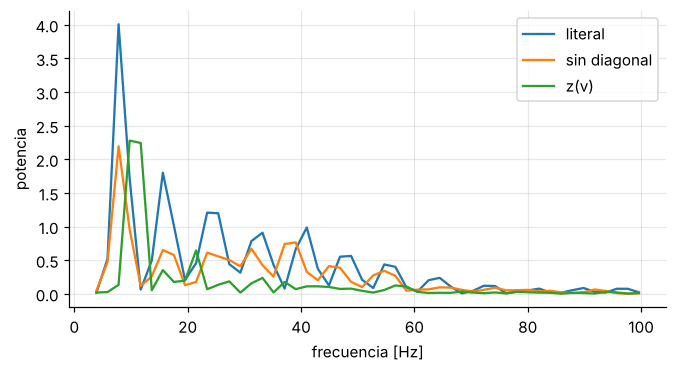

In [22]:
def actividad_poblacional(firings, T, N=1000, bin_ms=1.0):
    bins = np.arange(0, T + bin_ms, bin_ms)
    cuentas, _ = np.histogram(firings[:, 0], bins)
    return bins[:-1], cuentas/(N*bin_ms*1e-3)               # Hz por neurona

def espectro(firings, T, N=1000, descartar=100.0):
    from scipy.signal import welch
    tb, tasa = actividad_poblacional(firings, T, N)
    x = tasa[tb >= descartar]
    f, P = welch(x - x.mean(), fs=1000, nperseg=min(512, x.size))
    return f, P

plt.figure(figsize=(7, 3.5))
for nm, f in [('literal', f_lit), ('sin diagonal', f_sin), ('z(v)', f_z)]:
    fr, P = espectro(f, T); m = (fr > 2) & (fr < 100)
    plt.plot(fr[m], P[m], label=nm)
plt.xlabel('frecuencia [Hz]'); plt.ylabel('potencia'); plt.legend(); plt.show()